# Kalman filter experiments: how Managed Money's response to trend flow changes over time

**Question.** The Hormuz comment's Figure 3 shows a Brent-WTI divergence in trend positioning, and our NN struggles with WTI in 2026 while it holds up on Brent. Did trend followers move from WTI to Brent? We track the pass-through of trend flow into Managed Money (MM) as a drifting coefficient with error bands, in place of the fixed windows of `brent_crude_analysis.ipynb`.

**Findings.**

- **The Brent-WTI gap predates the war.** The probability that Brent's pass-through exceeds WTI's stays above 95% from 2025-04-01 (filtered) or 2024-04-02 (smoothed). Across six specifications the onset ranges from February 2024 to December 2025, always before March 2026.
- **It comes from WTI falling, not Brent rising.** Since December 2023 WTI's pass-through is down 0.241 (±0.188) and Brent's is down 0.109 (±0.131). The two drift together (correlation +0.91, negative values rejected), so we see no sign of money moving from one to the other.
- **Trend-flow regressors cannot see 2026.** Signals were capped, so flows were often zero. In simulation, a fall in WTI's pass-through to zero in March or May 2026 is detected at most 0.5% of the time by the filter and 6-10% by rolling OLS, against 5-6% false alarms by OLS. A flat beta in 2026 is therefore not evidence of no change.
- **The return can see 2026, and it points at WTI.** MM's response to the vol-scaled return falls from 9.1 in the pre-war year to about zero (change p = 0.001, robust to dropping weeks), while Brent's is 26.0 in May-August against 28.5. The return cannot say who stopped responding, and near-zero windows have precedent (3rd percentile).
- **As a nowcast, the filter gives protection and no new skill.** On signal flow it does not beat rolling OLS (-0.31 points [-1.18, 0.57]). As an overlay on the NN it does no harm in 2017-2025 (+0.82 [-1.43, 3.18]) and adds 11.47 points [3.47, 19.46] in May-August 2026, by shrinking the NN where it fails: WTI goes from -82.9% to -1.9%, about a zero forecast.
- **WTI is the only one of 18 markets clearly below its own history**, though this depends on the prior (z = -2.59, BH q = 0.043 at a common $q$; z = -2.05, q = 0.182 at WTI's own). Soybeans, sugar and corn are significantly higher. So we see no general exit from US-listed commodities on this measure. Refined products cannot be read: their signals were capped in 88-100% of May-August weeks.

**Limits.** Sections 3 to 6 and 8 use full-sample hyperparameters, and only section 7 is real-time. Signal flow comes from one replication rule, not from actual CTA books. Our NN is not the Hormuz variant (3 factors, 6 markets, 2-year window against their 1 neuron, 29 commodities, 1-year window). The 2026 windows are short and hand-picked, so we treat them as descriptive. We tested no causes, and everything here is association.

## Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import torch
from IPython.display import display
from matplotlib.lines import Line2D
from scipy import optimize, stats

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "working_ideas" else Path.cwd()
sys.path[:0] = [str(REPO_ROOT / "paper_replication" / "src"), str(REPO_ROOT / "working_ideas" / "src")]
import commodity_trend as ct
import kalman as kl
import sg_cta as sg
from paper_replication.config import ReplicationConfig

OUTPUT = REPO_ROOT / "paper_replication" / "outputs" / "kalman_filter"
OUTPUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", lambda v: f"{v:,.3f}")
BRENT, WTI, NN_COLOR, ZERO_COLOR, WAR_SHADE = "#277f8e", "#b7782c", "#1d4e89", "#8a8a8a", "#f3e6d8"
WAR, END = pd.Timestamp("2026-03-03"), pd.Timestamp("2026-08-25")
WINDOWS = {"Sep 2025-Feb 2026": ("2025-09-01", "2026-03-02"), "Mar-Apr 2026": ("2026-03-03", "2026-04-30"),
           "May-Aug 2026": ("2026-05-01", "2026-08-31")}

## Data

We regress the weekly change in Managed Money (MM) net position on a measure of trend flow, in thousand contracts, and let the coefficient drift:

$$y_t = x_t\,\beta_t + e_t, \qquad \beta_{t+1} = \beta_t + \eta_t, \qquad e_t \sim N(0, R), \quad \eta_t \sim N(0, Q).$$

$\beta_t$ is the pass-through of trend flow into MM. The Kalman filter gives $\beta_t$ with an error band, using data up to week $t$; the smoother uses the whole sample. We use three regressors: the signal flow implied by the 16-futures SG replication, the same replication's total position change, and the neural network's (NN) out-of-sample nowcast. The vol-scaled return is a fourth, in section 6.

In [2]:
T = ct.trend_panel(REPO_ROOT / "working_ideas" / "data_required", REPO_ROOT / "paper_replication" / "data_required",
                   "2026-08-25")
d_mm, flow, sizing, d_pos = (frame / 1e3 for frame in (T.d_mm, T.signal_flow, T.sizing_flow, T.d_pos))
z = T.ret / T.ret.rolling(26, min_periods=13).std().shift(1)

config = ReplicationConfig(data_dir=REPO_ROOT / "paper_replication" / "data_required", basis="futures_only",
                           train_weeks=104, seed=7, evaluation_end="2026-12-31")
panel, _ = sg.load_weekly_data(config)
decomposition, _ = sg.run_decomposition(panel, config)
nn = decomposition.merge(panel[sg.KEYS + ["actual_change", "mm_std_lag", "panel_date"]], on=sg.KEYS)
nn["predicted_change"] = nn["mm_std_lag"] * (nn["trend_cur"] - nn["trend_prev"])
nn_pred = nn.pivot(index="report_week_tuesday", columns="market", values="predicted_change") / 1e3

gap = (nn.set_index(sg.KEYS)["actual_change"] / 1e3 - d_mm.stack().rename_axis(sg.KEYS)).dropna().abs().max()
print(f"Weeks in the panel: {len(d_mm)}, {d_mm.index[0]:%Y-%m-%d} to {d_mm.index[-1]:%Y-%m-%d}; "
      f"NN nowcast from {nn_pred.index[0]:%Y-%m-%d}; largest gap between the two MM series: {gap:.2e} thousand contracts")

Weeks in the panel: 921, 2009-01-06 to 2026-08-25; NN nowcast from 2015-01-06; largest gap between the two MM series: 0.00e+00 thousand contracts


## 1. Do the tools work?

Our filter is hand-written so that the likelihood can be evaluated quickly thousands of times. Before using it, we compare it with `statsmodels` at the same parameters on WTI.

In [3]:
class RandomCoefficient(sm.tsa.statespace.MLEModel):
    """y_t = x_t beta_t + e_t with a random-walk beta, for the cross-check."""

    def __init__(self, y, x):
        super().__init__(y, k_states=1, k_posdef=1)
        self["design"] = x[None, None, :]
        self["transition", 0, 0] = 1.0
        self["selection", 0, 0] = 1.0

    def update(self, params, **kwargs):
        params = super().update(params, **kwargs)
        self["obs_cov", 0, 0], self["state_cov", 0, 0] = params


y, x = kl.clean_xy(d_mm["WTI"].loc["2011-01-11":], flow["WTI"].loc["2011-01-11":])
mle = kl.uni_mle(y, x)
R, Q = mle["R"], mle["Q"] if mle["Q"] > 0 else 1e-5
scalar = kl.uni_fit(y, x, q=Q / R)
filtered = kl.kf(y, x[:, None, None], np.array([[R]]), np.array([[Q]]), np.zeros(1), np.array([[kl.KAPPA * R]]))
smoothed = kl.smooth(filtered)
model = RandomCoefficient(y, x)
model.initialize_known(np.zeros(1), np.array([[kl.KAPPA * R]]))
result = model.smooth(np.array([R, Q]))
check = pd.Series({"Log-likelihood, general filter minus statsmodels": filtered["ll"].sum() - result.llf,
                   "Largest gap in filtered beta": np.abs(filtered["a_filt"][:, 0] - result.filtered_state[0]).max(),
                   "Largest gap in smoothed beta": np.abs(smoothed["a_s"][:, 0] - result.smoothed_state[0]).max(),
                   "Largest gap, scalar filter vs general filter": np.abs(scalar["a_f"] - filtered["a_filt"][:, 0]).max(),
                   "Largest gap, scalar smoother vs general": np.abs(scalar["a_s"] - smoothed["a_s"][:, 0]).max()})
print(check.map("{:.1e}".format).to_string())

Log-likelihood, general filter minus statsmodels    3.0e-08
Largest gap in filtered beta                        3.4e-08
Largest gap in smoothed beta                        7.3e-09
Largest gap, scalar filter vs general filter        2.6e-08
Largest gap, scalar smoother vs general             3.4e-10


## 2. Which trend flow?

The replication's position splits exactly into signal flow, where the signals change, and sizing flow, where volatility and price change the contract count. When signals sit at their cap the signal flow is zero and only sizing moves. If MM follows signals, sizing flow should carry little weight.

In [4]:
rows = []
for market in ct.ENERGY + ct.OTHER:
    data = pd.concat([d_mm[market], flow[market], sizing[market]], axis=1, keys=["y", "signal", "sizing"]).dropna()
    fit = sm.OLS(data["y"], data[["signal", "sizing"]]).fit(cov_type="HC3")
    test = fit.t_test("signal - sizing = 0")
    rows.append({"Market": market, "Weeks": len(data), "On signal flow": fit.params["signal"],
                 "On sizing flow": fit.params["sizing"], "t of the difference": test.tvalue.item()})
loadings = pd.DataFrame(rows).set_index("Market")
print(f"Median loading: signal {loadings['On signal flow'].median():.3f}, sizing {loadings['On sizing flow'].median():.3f}. "
      f"Signal above sizing in {(loadings['On signal flow'] > loadings['On sizing flow']).sum()} of 18 markets, "
      f"with t above 1.96 in {(loadings['t of the difference'] > 1.96).sum()}.")
display(loadings)

Median loading: signal 0.064, sizing 0.003. Signal above sizing in 18 of 18 markets, with t above 1.96 in 13.


,Weeks,On signal flow,On sizing flow,t of the difference
Market,,,,
BRENT,816,0.219,-0.036,3.978
WTI,920,0.200,-0.007,3.118
GASOIL,816,0.085,0.032,2.643
HEATOIL,869,0.057,0.000,3.474
RBOB,869,0.061,-0.016,4.362
NATGAS,920,0.111,0.067,1.601
GC,920,0.177,0.084,1.642
SI,920,0.069,0.046,0.961
PL,920,0.022,0.006,2.588


**Reading.** MM follows signals, not sizing. The median loading is 0.064 on signal flow and 0.003 on sizing flow. Signal flow has the larger loading in all 18 markets, with the difference above t = 1.96 in 13. So signal flow is our baseline regressor. It also behaves sensibly in capped weeks: it is zero, so the filter stops updating and its band widens, rather than learning from a flow MM does not follow.

The filter can only learn in weeks when the regressor moves. So we measure how much information each 2026 window holds: the share of weeks with signal flow at exactly zero, the share with at least two of the three signals capped, and the standard error a slope from that window alone would have, using the noise of 2015-2024 (a lower bound, since war-time noise is larger).

In [5]:
rows = []
for market in ct.ENERGY:
    base = pd.concat([d_mm[market], flow[market]], axis=1, keys=["y", "x"]).loc["2015":"2024"].dropna()
    slope = base["x"] @ base["y"] / (base["x"] @ base["x"])
    noise = ((base["y"] - slope * base["x"]) ** 2).mean()
    row = {"Market": market, "Slope 2015-2024": slope}
    for label, (start, end) in WINDOWS.items():
        x_window = flow[market].loc[start:end]
        sxx = (x_window ** 2).sum()
        row[f"{label}: zero flow"] = (x_window.abs() < 1e-6).mean()
        row[f"{label}: 2+ capped"] = (T.n_capped[market].loc[start:end] >= 2).mean()
        row[f"{label}: se"] = np.sqrt(noise / sxx) if sxx > 1e-9 else np.inf
    rows.append(row)
information = pd.DataFrame(rows).set_index("Market")
display(information.T)

Market,BRENT,WTI,GASOIL,HEATOIL,RBOB,NATGAS
Slope 2015-2024,0.249,0.246,0.100,0.057,0.069,0.109
Sep 2025-Feb 2026: zero flow,0.000,0.000,0.000,0.000,0.000,0.000
Sep 2025-Feb 2026: 2+ capped,0.000,0.000,0.077,0.115,0.000,0.038
Sep 2025-Feb 2026: se,0.061,0.061,0.040,0.024,0.017,0.050
Mar-Apr 2026: zero flow,0.667,0.111,0.889,0.889,0.667,0.000
Mar-Apr 2026: 2+ capped,1.000,0.556,1.000,1.000,0.889,0.000
Mar-Apr 2026: se,0.183,0.128,0.146,1.918,0.048,0.297
May-Aug 2026: zero flow,0.294,0.059,0.353,0.353,0.353,0.000
May-Aug 2026: 2+ capped,0.529,0.294,0.882,1.000,1.000,0.000
May-Aug 2026: se,0.317,0.298,0.404,0.223,0.200,0.064


**Reading.** The 2026 windows hold little information, and this limits every 2026 statement below. Brent's signal flow was exactly zero in 67% of March-April weeks, and the products' in 67-89%. In May-August a slope from the window alone would have a standard error of at least 0.32 for Brent and 0.30 for WTI, larger than their 2015-2024 slopes of 0.25, so it could not separate those slopes from zero. Gasoil, heating oil and RBOB had two or more signals capped in 88-100% of May-August weeks, so we draw no 2026 conclusion for products from flows.

## 3. Does beta move at all?

For each market and regressor we estimate $q_n = Q\,\overline{x^2}/R$, the signal-to-noise ratio, by maximum likelihood. Constancy sits on the boundary of the parameter space, so we bootstrap both tests with a wild bootstrap: the likelihood ratio, and the Nyblom-Hansen statistic $L_r$, robust to changing noise.

In [6]:
rows = []
for market in ["BRENT", "WTI"]:
    for name, X in {"Signal flow": flow, "NN nowcast": nn_pred}.items():
        first = X[market].first_valid_index()
        y, x = kl.clean_xy(d_mm[market].reindex(X.index).loc[first:], X[market].loc[first:])
        mle, hansen = kl.uni_mle(y, x), kl.nyblom(y, x, B=999)
        lr, p, cut = kl.wild_lr(y, x)
        rows.append({"Market": market, "Regressor": name, "Weeks": mle["n"], "Constant beta": hansen["b"], "q_n": mle["qn"],
                     "SD of beta per year": np.sqrt(52 * mle["Q"]), "LR": lr, "LR p": p, "LR 95% cut-off": cut,
                     "L_r": hansen["Lr"], "L_r p": hansen["p_r"]})
stability = pd.DataFrame(rows).set_index(["Market", "Regressor"])
print(stability.assign(q_n=stability["q_n"].map("{:.1e}".format)).to_string())

                    Weeks  Constant beta      q_n  SD of beta per year     LR  LR p  LR 95% cut-off   L_r  L_r p
Market Regressor                                                                                                
BRENT  Signal flow    816          0.219  2.8e-04                0.040 25.109 0.001           7.529 1.838  0.001
       NN nowcast     608          1.000  6.0e-03                0.538 16.256 0.001           2.760 0.149  0.396
WTI    Signal flow    920          0.200  1.8e-03                0.090 27.231 0.001           4.955 0.349  0.051
       NN nowcast     608          0.910  9.0e-03                0.682 56.681 0.001           6.537 0.301  0.088


**Reading.** Beta is not constant. The likelihood ratio rejects constancy for both markets on both regressors (each p = 0.001, the smallest possible with 999 draws). $L_r$ agrees for Brent on signal flow (0.001) and is borderline for WTI (0.051), but does not reject on the NN nowcast (0.396 and 0.088). $L_r$ is built from partial sums that return to zero by construction at the end of the sample, so it can miss a late change, and we do not read those values as stability. On signal flow, beta drifts by about 0.04 a year for Brent and 0.09 for WTI, around levels near 0.2.

## 4. Brent and WTI together

The bivariate model lets the two betas share noise in the observation and in the drift, with full $2 \times 2$ matrices $R$ and $Q$. Two questions matter here.

- **Substitution.** If trend followers moved out of WTI and into Brent, the shocks to the two betas should be negatively correlated, so $\rho_Q < 0$.
- **Tilt.** $P(\beta^{B}_t > \beta^{W}_t \mid \text{data})$, and the week from which it stays above 95%.

The hyperparameters are estimated on the full sample, so the filtered paths here are not truly real-time. Section 7 is.

In [7]:
def bivariate_data(x_brent, x_wti, start="2011-01-11", brent=None, wti=None):
    data = pd.concat([d_mm["BRENT"] if brent is None else brent, d_mm["WTI"] if wti is None else wti, x_brent, x_wti],
                     axis=1, keys=["yB", "yW", "xB", "xW"]).loc[start:]
    yB, yW = np.where(data["xB"].isna(), np.nan, data["yB"]), np.where(data["xW"].isna(), np.nan, data["yW"])
    return data.index, yB, yW, data["xB"].fillna(0).to_numpy(), data["xW"].fillna(0).to_numpy()


def starting_values(yB, yW, xB, xW):
    mB, mW = kl.uni_mle(yB, xB), kl.uni_mle(yW, xW)
    bB, bW = np.nansum(xB * yB) / np.nansum(xB[np.isfinite(yB)] ** 2), np.nansum(xW * yW) / np.nansum(xW[np.isfinite(yW)] ** 2)
    eB, eW = yB - bB * xB, yW - bW * xW
    both = np.isfinite(eB) & np.isfinite(eW)
    rho = np.corrcoef(eB[both], eW[both])[0, 1]
    return [np.array([np.log(mB["R"]), np.log(mW["R"]), np.arctanh(rho), np.log(max(mB["Q"], 1e-6)), np.log(max(mW["Q"], 1e-6)),
                      np.arctanh(rho_q)]) for rho_q in (0.0, -0.5, 0.5)]


def fit_bivariate(x_brent, x_wti, start="2011-01-11", ewma=False):
    """Maximum likelihood, filter and smoother. With `ewma`, R_t follows a lagged EWMA of the errors of a first fit."""
    index, yB, yW, xB, xW = bivariate_data(x_brent, x_wti, start)
    fit = kl.bi_mle(yB, yW, xB, xW, starting_values(yB, yW, xB, xW))
    filtered, smoothed = kl.bi_run(yB, yW, xB, xW, fit["R"], fit["Q"])
    if ewma:
        s1, s2 = kl.ewma_scale(filtered["v"][:, 0]), kl.ewma_scale(filtered["v"][:, 1])
        fit = kl.bi_mle(yB, yW, xB, xW, [fit["theta"]], s1, s2)
        R = fit["R"]
        path = np.empty((len(index), 2, 2))
        path[:, 0, 0], path[:, 1, 1], path[:, 0, 1] = R[0, 0] * s1, R[1, 1] * s2, R[0, 1] * np.sqrt(s1 * s2)
        path[:, 1, 0] = path[:, 0, 1]
        filtered, smoothed = kl.bi_run(yB, yW, xB, xW, R, fit["Q"], Rt=path)
    paths = pd.DataFrame({"beta_B_f": filtered["a_filt"][:, 0], "beta_W_f": filtered["a_filt"][:, 1],
                          "beta_B_s": smoothed["a_s"][:, 0], "beta_W_s": smoothed["a_s"][:, 1],
                          "sd_B_f": np.sqrt(filtered["P_filt"][:, 0, 0]), "sd_W_f": np.sqrt(filtered["P_filt"][:, 1, 1]),
                          "sd_B_s": np.sqrt(smoothed["P_s"][:, 0, 0]), "sd_W_s": np.sqrt(smoothed["P_s"][:, 1, 1]),
                          "tilt_f": [kl.tilt(a, P)[0] for a, P in zip(filtered["a_filt"], filtered["P_filt"])],
                          "tilt_s": [kl.tilt(a, P)[0] for a, P in zip(smoothed["a_s"], smoothed["P_s"])]}, index=index)
    paths["sd_spread_s"] = [kl.tilt(a, P)[2] for a, P in zip(smoothed["a_s"], smoothed["P_s"])]
    return dict(fit=fit, filtered=filtered, smoothed=smoothed, paths=paths, data=(index, yB, yW, xB, xW))


base = fit_bivariate(flow["BRENT"], flow["WTI"])
fit = base["fit"]
index, yB, yW, xB, xW = base["data"]


def profile_rho_q(rho_q):
    def nll(th):
        q1, q2 = np.exp(th[3]), np.exp(th[4])
        return -kl.bi_ll(yB.tolist(), yW.tolist(), xB.tolist(), xW.tolist(), np.exp(th[0]), np.exp(th[1]),
                         np.tanh(th[2]) * np.exp(0.5 * (th[0] + th[1])), q1, q2, rho_q * np.sqrt(q1 * q2))
    best = optimize.minimize(nll, fit["theta"][:5], method="Nelder-Mead", options=dict(maxiter=1500, xatol=2e-3, fatol=1e-3, adaptive=True))
    return 2 * (fit["ll"] + best.fun)


print(f"Noise correlation rho_R {fit['rho_R']:.3f}; drift correlation rho_Q {fit['rho_Q']:.3f}; "
      f"SD of beta per year: Brent {np.sqrt(52 * fit['Q'][0, 0]):.3f}, WTI {np.sqrt(52 * fit['Q'][1, 1]):.3f}")
pd.Series({rho: profile_rho_q(rho) for rho in (-0.5, 0.0, 0.5)}, name="LR against the MLE (5% cut-off 3.84)").rename_axis("rho_Q").to_frame()

Noise correlation rho_R 0.312; drift correlation rho_Q 0.908; SD of beta per year: Brent 0.064, WTI 0.099


,LR against the MLE (5% cut-off 3.84)
rho_Q,
-0.500,7.940
0.000,4.583
0.500,1.988


**Reading.** There is no sign of substitution. The drift correlation is +0.91: when one pass-through falls, the other tends to fall too. A correlation of -0.5 is rejected (LR 7.94), and so is zero (4.58), against the 3.84 cut-off, while +0.5 is not (1.99). Money leaving WTI for Brent would push this the other way. Only the sign is well determined; the exact value is not.

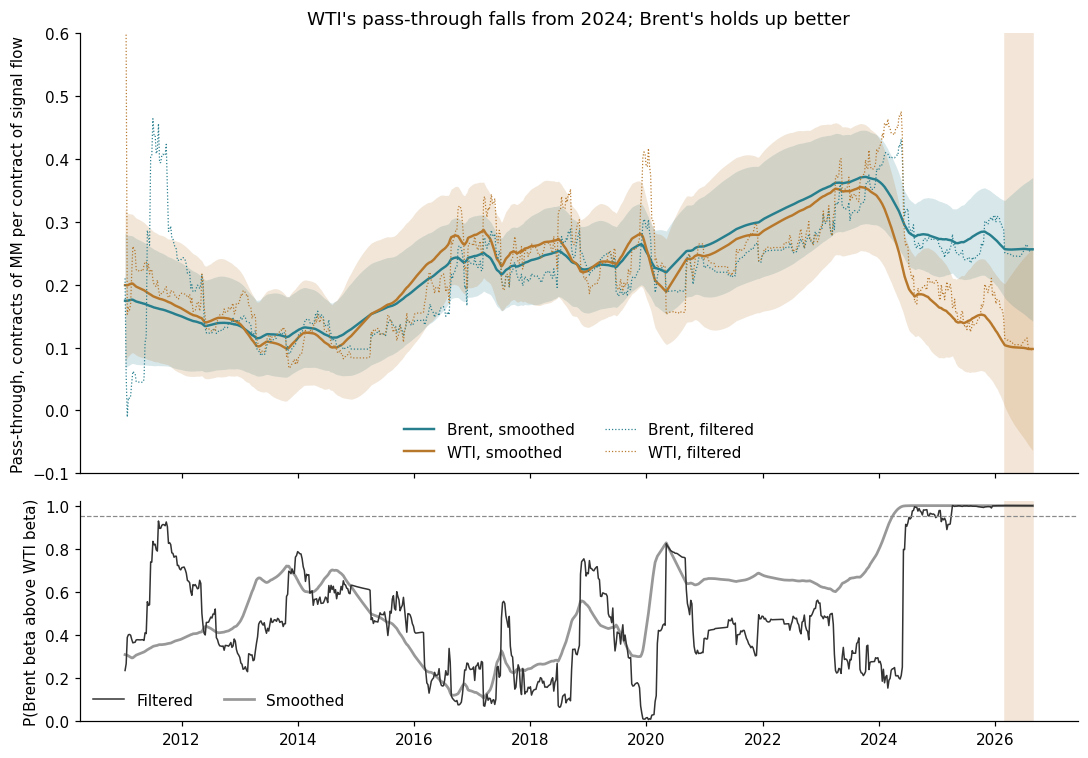

Share of 2012-2025 weeks with filtered tilt above 95%: 0.088
Filtered tilt stays above 95% from 2025-04-01; smoothed from 2024-04-02
Filtered tilt above 95% for 4+ weeks: ['2024-07-30 to 2024-12-17 (21 wks)', '2025-04-01 to 2026-08-25 (74 wks)']


In [8]:
paths = base["paths"]
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, height_ratios=[2, 1])
for name, color, b, sd in [("Brent", BRENT, "beta_B_s", "sd_B_s"), ("WTI", WTI, "beta_W_s", "sd_W_s")]:
    axes[0].plot(paths.index, paths[b], color=color, lw=1.6, label=f"{name}, smoothed")
    axes[0].fill_between(paths.index, paths[b] - 1.96 * paths[sd], paths[b] + 1.96 * paths[sd], color=color, alpha=0.18, lw=0)
axes[0].plot(paths.index, paths["beta_B_f"], color=BRENT, lw=0.8, ls=":", label="Brent, filtered")
axes[0].plot(paths.index, paths["beta_W_f"], color=WTI, lw=0.8, ls=":", label="WTI, filtered")
axes[0].set(ylim=(-0.1, 0.6), ylabel="Pass-through, contracts of MM per contract of signal flow",
            title="WTI's pass-through falls from 2024; Brent's holds up better")
axes[0].legend(frameon=False, ncol=2)
axes[1].plot(paths.index, paths["tilt_f"], color="#333333", lw=1, label="Filtered")
axes[1].plot(paths.index, paths["tilt_s"], color="#333333", lw=1.8, alpha=0.5, label="Smoothed")
axes[1].axhline(0.95, color=ZERO_COLOR, lw=0.8, ls="--")
axes[1].set(ylabel="P(Brent beta above WTI beta)", ylim=(0, 1.02))
axes[1].legend(frameon=False, ncol=2, loc="lower left")
for ax in axes:
    ax.axvspan(WAR, END, color=WAR_SHADE, zorder=0)
fig.tight_layout()
fig.savefig(OUTPUT / "beta_paths.png", dpi=170)
plt.show()

history = paths.loc["2012":"2025"]
print(f"Share of 2012-2025 weeks with filtered tilt above 95%: {(history['tilt_f'] > 0.95).mean():.3f}")
print(f"Filtered tilt stays above 95% from {kl.stays_above(paths['tilt_f'], 0.95):%Y-%m-%d}; "
      f"smoothed from {kl.stays_above(paths['tilt_s'], 0.95):%Y-%m-%d}")
above = paths["tilt_f"] > 0.95
episodes = paths[above].groupby((above != above.shift()).cumsum()[above]).apply(lambda g: (g.index[0], g.index[-1], len(g)), include_groups=False)
print("Filtered tilt above 95% for 4+ weeks:", [f"{a:%Y-%m-%d} to {b:%Y-%m-%d} ({n} wks)" for a, b, n in episodes if n >= 4])

Tilt alone can mislead, since constant betas with a gap would give a high tilt too. So we also report how much each beta changed, from the joint smoothed distribution. The last column compares the posterior sd of the spread change with its prior sd: when the two are about equal, the data have added nothing and the model cannot tell.

In [9]:
smoothed, Q_ = base["smoothed"], fit["Q"]
last, c = len(index) - 1, np.array([1.0, -1.0])
rows = []
for since in ["2019-12-31", "2022-12-27", "2023-12-26", "2024-12-31", "2025-12-30", "2026-02-24", "2026-04-28"]:
    i = index.searchsorted(pd.Timestamp(since), side="right") - 1
    cov = kl.joint_cov(smoothed["P_s"], smoothed["J"], i, last)
    V = smoothed["P_s"][i] + smoothed["P_s"][last] - cov - cov.T
    dB, dW = smoothed["a_s"][last] - smoothed["a_s"][i]
    rows.append({"Since": f"{index[i]:%Y-%m-%d}", "Change in Brent": dB, "95% half-width, Brent": 1.96 * np.sqrt(V[0, 0]),
                 "Change in WTI": dW, "95% half-width, WTI": 1.96 * np.sqrt(V[1, 1]), "Change in spread": dB - dW,
                 "Posterior sd": np.sqrt(c @ V @ c), "Prior sd": np.sqrt((last - i) * (c @ Q_ @ c))})
changes = pd.DataFrame(rows).set_index("Since")
print(f"End of sample: Brent {paths['beta_B_s'].iloc[-1]:.3f} (sd {paths['sd_B_s'].iloc[-1]:.3f}), "
      f"WTI {paths['beta_W_s'].iloc[-1]:.3f} (sd {paths['sd_W_s'].iloc[-1]:.3f})")
changes

End of sample: Brent 0.256 (sd 0.058), WTI 0.098 (sd 0.082)


,Change in Brent,"95% half-width, Brent",Change in WTI,"95% half-width, WTI",Change in spread,Posterior sd,Prior sd
Since,,,,,,,
2019-12-31,0.004,0.129,-0.160,0.180,0.164,0.058,0.126
2022-12-27,-0.093,0.140,-0.239,0.199,0.146,0.061,0.094
2023-12-26,-0.109,0.131,-0.241,0.188,0.132,0.056,0.080
2024-12-31,-0.018,0.121,-0.070,0.179,0.052,0.050,0.063
2025-12-30,-0.016,0.098,-0.032,0.151,0.015,0.038,0.040
2026-02-24,-0.002,0.087,-0.009,0.135,0.007,0.034,0.035
2026-04-28,0.000,0.071,-0.003,0.110,0.003,0.028,0.028


**Reading.**

- **The gap opened before the war.** The filtered tilt stays above 95% from 2025-04-01, eleven months before the war, and the smoothed tilt from 2024-04-02. Only one earlier episode of four or more weeks reached 95%, from 2024-07-30 to 2024-12-17, and it is part of the same move. These two episodes make up nearly all of the 8.8% of 2012-2025 weeks above 95%.
- **WTI fell and Brent did not rise.** Since December 2023, WTI's beta is down 0.241 (±0.188) and Brent's is down 0.109 (±0.131), so the spread widened by 0.132 (posterior sd 0.056). Money moving into Brent would have raised Brent's beta. The sample ends with Brent at 0.256 and WTI at 0.098. The dates in this table are for description, picked after seeing the chart.
- **The model cannot speak to 2026.** Since 2025-12-30 the spread moved by 0.015, with a posterior sd of 0.038 against a prior sd of 0.040. Since 2026-02-24 it moved by 0.007, with 0.034 against 0.035. The data added almost nothing, which is different from saying nothing changed. Section 5 measures how blind the filter is.

### Robustness of the dating and the end-of-sample gap

In [10]:
common = 0.5 * (flow["BRENT"] + flow["WTI"])
variants = {"Baseline: own signal flow": base,
            "EWMA R_t": fit_bivariate(flow["BRENT"], flow["WTI"], ewma=True),
            "Total position change": fit_bivariate(d_pos["BRENT"], d_pos["WTI"]),
            "Common flow (average of the two)": fit_bivariate(common, common),
            "Sample from 2015": fit_bivariate(flow["BRENT"], flow["WTI"], start="2015-01-06"),
            "NN nowcast": fit_bivariate(nn_pred["BRENT"].reindex(d_mm.index), nn_pred["WTI"].reindex(d_mm.index), start=nn_pred.index[0])}
rows = []
for name, variant in variants.items():
    p = variant["paths"]
    first_f, first_s = kl.stays_above(p["tilt_f"], 0.95), kl.stays_above(p["tilt_s"], 0.95)
    rows.append({"Specification": name, "rho_Q": variant["fit"]["rho_Q"], "Brent, end": p["beta_B_s"].iloc[-1], "WTI, end": p["beta_W_s"].iloc[-1],
                 "Filtered tilt, end": p["tilt_f"].iloc[-1], "Filtered tilt stays above 95% from": "never" if first_f is None else f"{first_f:%Y-%m-%d}",
                 "Smoothed tilt stays above 95% from": "never" if first_s is None else f"{first_s:%Y-%m-%d}"})
robustness = pd.DataFrame(rows).set_index("Specification")
robustness

,rho_Q,"Brent, end","WTI, end","Filtered tilt, end",Filtered tilt stays above 95% from,Smoothed tilt stays above 95% from
Specification,,,,,,
Baseline: own signal flow,0.908,0.256,0.098,0.999,2025-04-01,2024-04-02
EWMA R_t,0.877,0.222,0.073,0.999,2025-04-08,2024-02-13
Total position change,0.947,0.231,0.062,0.998,2025-04-01,2024-04-23
Common flow (average of the two),0.942,0.255,0.082,0.997,2025-04-01,2024-04-16
Sample from 2015,0.877,0.257,0.073,0.995,2025-12-16,2024-05-21
NN nowcast,0.806,1.069,0.258,0.996,2025-12-16,2025-08-05


**Reading.** The pre-war dating holds in all six specifications. The filtered tilt settles above 95% between 2025-04-01 and 2025-12-16, and the smoothed tilt between 2024-02-13 and 2025-08-05. So the onset is a range, not a date, and it is always before March 2026. $\rho_Q$ stays positive throughout (0.81 to 0.95). The NN row is the direct version of the team's observation: pass-through of the NN's nowcast ends at 1.07 for Brent and 0.26 for WTI. The end-of-sample tilt saturates (0.995 to 0.999), which is why we rely on the spread and its change.

## 5. Could the filter see a change in 2026?

A filter that does not move in 2026 is not evidence that nothing changed. We test this directly by simulation, using WTI's actual signal flow and its actual residuals with random signs (a wild bootstrap, so the war-time noise is kept). We plant a fall in beta to zero at a known date and ask how often each method's upper 95% band lands below the old beta by the last week.

In [11]:
y, x = kl.clean_xy(d_mm["WTI"].loc["2011-01-11":], flow["WTI"].loc["2011-01-11":])
dates = d_mm.loc["2011-01-11":].index
obs = np.isfinite(y)
beta0 = x[obs] @ y[obs] / (x[obs] @ x[obs])
residual = y - beta0 * x
mle = kl.uni_mle(y, x)
q_median = np.median([m["qn"] for m in (kl.uni_mle(*kl.clean_xy(d_mm[k].loc["2011-01-11":], flow[k].loc["2011-01-11":])) for k in ct.ENERGY + ct.OTHER)]) / mle["scale"]
print(f"WTI: constant beta {beta0:.3f}; q_n at the MLE {mle['qn']:.2e}; median q_n across the 18 markets {q_median * mle['scale']:.2e}")
rng = np.random.default_rng(7)
signs = rng.choice([-1.0, 1.0], size=(len(y), 2000))


def ols_upper(Y, x, window):
    Y_, x_ = Y[-window:], x[-window:]
    ok = np.isfinite(Y_[:, 0])
    Y_, x_ = Y_[ok], x_[ok]
    b = (x_ @ Y_) / (x_ @ x_)
    e = Y_ - np.outer(x_, b)
    se = np.sqrt((x_[:, None] ** 2 * e ** 2).sum(0)) / (x_ @ x_)
    return b + 1.96 * se


rows = []
for label, date in {"No change": None, "Falls to 0 in June 2024": "2024-06-04", "Falls to 0 at the war, March 2026": "2026-03-03", "Falls to 0 in May 2026": "2026-05-05"}.items():
    beta = np.full(len(y), beta0)
    if date:
        beta[dates >= pd.Timestamp(date)] = 0.0
    Y = (beta * x)[:, None] + residual[:, None] * signs
    row = {"True path": label}
    for name, q in {"Kalman, q at the MLE": mle["q"], "Kalman, median q": q_median, "Kalman, 10 x median q": 10 * q_median}.items():
        a, P = kl.end_of_sample(Y, x, q)
        row[name] = np.mean(a + 1.96 * np.sqrt(P * kl.uni_ll(y, x, q)[1]) < beta0)
    row["OLS, last 52 weeks"] = np.mean(ols_upper(Y, x, 52) < beta0)
    row["OLS, last 104 weeks"] = np.mean(ols_upper(Y, x, 104) < beta0)
    rows.append(row)
power = pd.DataFrame(rows).set_index("True path")
power

WTI: constant beta 0.196; q_n at the MLE 2.15e-03; median q_n across the 18 markets 3.85e-04


,"Kalman, q at the MLE","Kalman, median q","Kalman, 10 x median q","OLS, last 52 weeks","OLS, last 104 weeks"
True path,,,,,
No change,0.000,0.000,0.000,0.063,0.052
Falls to 0 in June 2024,0.749,1.000,0.489,1.000,1.000
"Falls to 0 at the war, March 2026",0.005,0.005,0.004,0.095,0.082
Falls to 0 in May 2026,0.000,0.001,0.000,0.083,0.057


**Reading.** Flows can see an old break but not a 2026 one. A fall to zero in June 2024 is found 49-100% of the time by the filter and always by rolling OLS. A fall at the war's start is found at most 0.5% of the time by the filter and 8-10% by OLS, whose false-alarm rate is 5-6%. A fall in May 2026 is found at most 0.1% of the time by the filter and 6-8% by OLS, about the same as no change at all. The filter raised no false alarm in 2,000 draws, but only because its band is wide. So a flat 2026 WTI beta in the charts above tells us nothing about 2026.

## 6. A regressor that does not vanish: the return

Flows stop informing the filter when signals are capped. The vol-scaled return $z_t$ (the week's return over the lagged 26-week standard deviation) always moves. It is not a trend measure: it mixes trend following with any other reaction to price, so it cannot say who is responding. It only asks whether MM still responds to price at all.

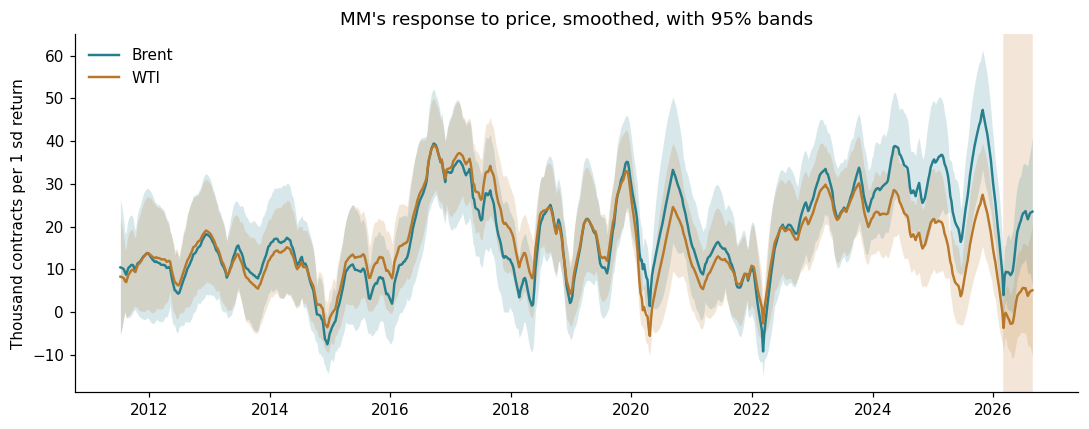

Weeks  Slope     Low   High
Market Period                                   
BRENT  2015-2024       522 13.603  10.193 17.014
       Pre-war year     52 28.529  19.410 37.647
       Mar-Apr 2026      9  1.071 -22.906 25.049
       May-Aug 2026     17 25.972  12.943 39.001
WTI    2015-2024       522 12.057   8.015 16.100
       Pre-war year     52  9.121   4.994 13.248
       Mar-Apr 2026      9 -1.312  -9.093  6.468
       May-Aug 2026     17  1.425  -6.496  9.347

Pre-war slope  Change after      t     p
Market Sample                                                                     
BRENT  All weeks                                 28.529       -19.430 -1.960 0.050
       Without the first three war weeks         28.529        -8.966 -1.199 0.230
       Without 2026-07-14 and 2026-08-11         28.529       -21.846 -2.269 0.023
WTI    All weeks                                  9.121        -9.539 -3.261 0.001
       Without the first three war weeks          9.121       -12.312 -3.636 0.000
       Without 2026-07-14 and 2026-08-11          9.121        -9.405 -3.180 0.001

,26-week slope to 2026-08-25,Percentile among windows ending by 2025,Share of those windows at or below zero,Lowest,Week of the lowest
Market,,,,,
BRENT,9.099,24.571,0.071,-7.310,2022-06-28
WTI,-0.419,3.062,0.041,-2.655,2020-09-01


In [12]:
ret_fit = fit_bivariate(z["BRENT"], z["WTI"], start="2011-07-12")
p_ret = ret_fit["paths"]
fig, ax = plt.subplots(figsize=(10, 4))
for name, color, b, sd in [("Brent", BRENT, "beta_B_s", "sd_B_s"), ("WTI", WTI, "beta_W_s", "sd_W_s")]:
    ax.plot(p_ret.index, p_ret[b], color=color, lw=1.6, label=name)
    ax.fill_between(p_ret.index, p_ret[b] - 1.96 * p_ret[sd], p_ret[b] + 1.96 * p_ret[sd], color=color, alpha=0.18, lw=0)
ax.axvspan(WAR, END, color=WAR_SHADE, zorder=0)
ax.set(ylabel="Thousand contracts per 1 sd return", title="MM's response to price, smoothed, with 95% bands")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT / "return_response.png", dpi=170)
plt.show()

PERIODS = {"2015-2024": ("2015-01-01", "2024-12-31"), "Pre-war year": ("2025-03-04", "2026-02-24"), **{k: v for k, v in WINDOWS.items() if k != "Sep 2025-Feb 2026"}}
rows = []
for market in ["BRENT", "WTI"]:
    for label, (start, end) in PERIODS.items():
        d = pd.concat([d_mm[market], z[market]], axis=1, keys=["y", "z"]).loc[start:end].dropna()
        ols = sm.OLS(d["y"], sm.add_constant(d["z"])).fit(cov_type="HC3")
        low, high = ols.conf_int().loc["z"]
        rows.append({"Market": market, "Period": label, "Weeks": len(d), "Slope": ols.params["z"], "Low": low, "High": high})
display(pd.DataFrame(rows).set_index(["Market", "Period"]))


def war_change(market, drop=()):
    """Slope after the war's start minus the pre-war year's, HC3."""
    d = pd.concat([d_mm[market], z[market]], axis=1, keys=["y", "z"]).loc["2025-03-04":"2026-08-25"].dropna().drop(pd.to_datetime(list(drop)), errors="ignore")
    post = (d.index >= WAR).astype(float)
    X = pd.DataFrame({"const": 1.0, "z": d["z"], "post": post, "post_z": post * d["z"]}, index=d.index)
    ols = sm.OLS(d["y"], X).fit(cov_type="HC3")
    return {"Pre-war slope": ols.params["z"], "Change after": ols.params["post_z"], "t": ols.tvalues["post_z"], "p": ols.pvalues["post_z"]}


FIRST_WAR_WEEKS = ["2026-03-03", "2026-03-10", "2026-03-17"]
rows = []
for market in ["BRENT", "WTI"]:
    for label, drop in {"All weeks": (), "Without the first three war weeks": FIRST_WAR_WEEKS, "Without 2026-07-14 and 2026-08-11": ["2026-07-14", "2026-08-11"]}.items():
        rows.append({"Market": market, "Sample": label} | war_change(market, drop))
war_test = pd.DataFrame(rows).set_index(["Market", "Sample"])
display(war_test)

rows = []
for market in ["BRENT", "WTI"]:
    d = pd.concat([d_mm[market], z[market]], axis=1, keys=["y", "z"]).dropna()
    slope = d["y"].rolling(26).cov(d["z"]) / d["z"].rolling(26).var()
    history = slope.loc[:"2025-12-31"].dropna()
    last = slope.iloc[-1]
    rows.append({"Market": market, "26-week slope to 2026-08-25": last, "Percentile among windows ending by 2025": 100 * (history < last).mean(),
                 "Share of those windows at or below zero": (history <= 0).mean(), "Lowest": history.min(), "Week of the lowest": f"{history.idxmin():%Y-%m-%d}"})
pd.DataFrame(rows).set_index("Market")

**Reading.** This is where 2026 shows up, and it shows up in WTI.

- **WTI.** The response was 9.1 [5.0, 13.2] in the pre-war year and near zero after: -1.3 [-9.1, 6.5] in March-April and 1.4 [-6.5, 9.3] in May-August. The fall of 9.5 is significant (t = -3.26, p = 0.001), and it survives dropping the first three war weeks, when lagged volatility had not caught up (-12.3, p < 0.001), and dropping 2026-07-14 and 2026-08-11 (-9.4, p = 0.001).
- **Brent.** The response collapsed in March-April (1.1, with a very wide interval) and came back to 26.0 [12.9, 39.0] in May-August, against 28.5 [19.4, 37.6] before. Its overall fall (-19.4, p = 0.05) is not robust: it is -9.0 (p = 0.23) without the first three war weeks.

Three limits apply. The gap exists before the war here too: 28.5 against 9.1 in the pre-war year. The windows are hand-picked, so the p-values are descriptive. And WTI's last 26-week slope (-0.4) is low but has precedent: it sits at the 3rd percentile of past windows, 4.1% of which were at or below zero, with the lowest in September 2020. The return also mixes every reason to react to price, so it cannot tell us that trend followers are the ones who stopped.

## Influence

The Brent notebook found that a single week, 2026-07-14, drove the window correlation for Brent. Here we drop that week, then each 2026 week in turn, at the baseline hyperparameters.

In [13]:
def end_state(drop):
    yB_, yW_ = yB.copy(), yW.copy()
    yB_[drop], yW_[drop] = np.nan, np.nan
    filtered, _ = kl.bi_run(yB_, yW_, xB, xW, fit["R"], fit["Q"])
    tilt, spread, _ = kl.tilt(filtered["a_filt"][-1], filtered["P_filt"][-1])
    return {"Brent": filtered["a_filt"][-1, 0], "WTI": filtered["a_filt"][-1, 1], "Spread": spread, "Tilt": tilt}


weeks_2026 = np.flatnonzero(index >= pd.Timestamp("2026-01-01"))
sweep = pd.DataFrame([end_state([i]) for i in weeks_2026], index=index[weeks_2026])
pd.DataFrame({"All weeks": end_state([]), "Without 2026-07-14": end_state([index.get_loc(pd.Timestamp("2026-07-14"))]),
              "Lowest, dropping any one 2026 week": sweep.min(), "Highest, dropping any one 2026 week": sweep.max()}).T

,Brent,WTI,Spread,Tilt
All weeks,0.256,0.098,0.159,0.999
Without 2026-07-14,0.248,0.095,0.153,0.999
"Lowest, dropping any one 2026 week",0.246,0.090,0.151,0.999
"Highest, dropping any one 2026 week",0.290,0.124,0.167,0.999


**Reading.** The Kalman results do not hang on that week. Dropping 2026-07-14 moves Brent's end beta from 0.256 to 0.248 and the spread from 0.159 to 0.153. Across every 2026 leave-one-out the spread stays between 0.151 and 0.167, and the tilt rounds to 0.999. That stability is partly the same slowness that keeps the filter from seeing 2026: it gives any single week little weight.

## 7. Does it help predict, in real time?

Everything so far used full-sample hyperparameters. Now $q$ and $R$ are re-estimated each January on prior data only, and the prediction for week $t$ is $\beta_{t|t-1} x_t$, with $\beta$ learned from weeks before $t$. We compare with a constant slope fitted on all past weeks, a rolling 104-week slope, and the NN, on the same 2,820 market-weeks as the earlier benchmark. "KF on NN" is the filter applied as an overlay: it rescales the NN's nowcast by a drifting pass-through.

In [14]:
predictions = {}
for label, X in {"signal flow": flow, "NN": nn_pred}.items():
    y_table, x_table = d_mm.reindex(X.index), X
    dates = X.index
    predictions[f"Constant slope on {label}"] = pd.DataFrame({m: kl.past_slope_prediction(y_table[m], x_table[m]) for m in sg.MARKETS}, index=dates)
    predictions[f"Rolling 104-week slope on {label}"] = pd.DataFrame({m: kl.past_slope_prediction(y_table[m], x_table[m], 104) for m in sg.MARKETS}, index=dates)
    predictions[f"KF on {label}"] = pd.DataFrame({m: kl.realtime_prediction(y_table[m], x_table[m], dates, 2012) for m in sg.MARKETS}, index=dates)

scored = nn[sg.KEYS + ["panel_date", "actual_change", "predicted_change"]].rename(columns={"predicted_change": "NN"})
for name, frame in predictions.items():
    scored = scored.merge((frame * 1e3).stack().rename(name).rename_axis(sg.KEYS).reset_index(), on=sg.KEYS, how="left")
scored["Zero"] = 0.0
METHODS = ["NN", "KF on NN", "Rolling 104-week slope on NN", "Constant slope on NN", "KF on signal flow",
           "Rolling 104-week slope on signal flow", "Constant slope on signal flow"]
SAMPLES = {"2017-2025": ("2017-01-01", "2025-12-31"), "Jan-Aug 2026": ("2026-01-01", "2026-08-31"), "May-Aug 2026": ("2026-05-01", "2026-08-31")}
samples = {label: sg.common_sample(scored, start, end) for label, (start, end) in SAMPLES.items()}
print({label: len(frame) for label, frame in samples.items()})
display(pd.DataFrame({label: {m: sg.score(frame.dropna(subset=[m]), m)["R² (%)"] for m in METHODS} for label, frame in samples.items()}).rename_axis("R² (%)"))
display(pd.DataFrame({market: {m: sg.score(samples["May-Aug 2026"].query("market == @market"), m)["R² (%)"] for m in METHODS} for market in sg.MARKETS}).rename_axis("R² (%), May-Aug 2026"))
rows = []
for base_name, model_name in [("Rolling 104-week slope on signal flow", "KF on signal flow"), ("Constant slope on signal flow", "KF on signal flow"),
                              ("KF on signal flow", "NN"), ("NN", "KF on NN")]:
    for label, frame in samples.items():
        estimate, low, high = kl.r2_gain(frame, base_name, model_name, block=13 if label == "2017-2025" else 4)
        rows.append({"Model": model_name, "Against": base_name, "Sample": label, "R² gain": estimate, "Low": low, "High": high})
gains = pd.DataFrame(rows).set_index(["Model", "Against", "Sample"])
gains

{'2017-2025': 2820, 'Jan-Aug 2026': 204, 'May-Aug 2026': 102}


,2017-2025,Jan-Aug 2026,May-Aug 2026
R² (%),,,
NN,44.903,34.608,43.457
KF on NN,45.725,39.473,54.924
Rolling 104-week slope on NN,43.624,38.588,47.885
Constant slope on NN,44.172,36.783,45.871
KF on signal flow,29.921,11.565,14.109
Rolling 104-week slope on signal flow,30.232,12.647,12.702
Constant slope on signal flow,29.222,11.465,12.200


,WTI,BRENT,GASOIL,HEATOIL,RBOB,NATGAS
"R² (%), May-Aug 2026",,,,,,
NN,-82.882,71.375,-264.666,6.915,-114.359,45.238
KF on NN,-1.862,70.081,-53.066,22.570,-23.082,48.920
Rolling 104-week slope on NN,-33.914,69.633,-133.821,23.758,-35.164,39.769
Constant slope on NN,-67.390,71.284,-184.711,14.937,-61.858,43.436
KF on signal flow,-8.133,20.560,-6.785,14.268,-9.126,9.156
Rolling 104-week slope on signal flow,-13.137,19.345,-6.030,11.507,-9.394,8.399
Constant slope on signal flow,-20.748,16.259,-4.556,13.223,-8.335,15.614


R² gain    Low   High
Model             Against                               Sample                             
KF on signal flow Rolling 104-week slope on signal flow 2017-2025      -0.311 -1.179  0.572
                                                        Jan-Aug 2026   -1.082 -3.863  1.367
                                                        May-Aug 2026    1.406  0.511  2.471
                  Constant slope on signal flow         2017-2025       0.699 -1.457  2.768
                                                        Jan-Aug 2026    0.101 -6.111  5.213
                                                        May-Aug 2026    1.909 -3.318  5.977
NN                KF on signal flow                     2017-2025      14.982 10.269 19.863
                                                        Jan-Aug 2026   23.042  3.151 44.030
                                                        May-Aug 2026   29.349 16.889 47.057
KF on NN          NN                                    2017-2025       0.821 -1.429  3.184
                                                        Jan-Aug 2026    4.865 -1.454 12.696
                                                        May-Aug 2026   11.466  3.469 19.462

**Reading.**

- **The filter does not beat OLS on flows.** On 2017-2025, KF on signal flow gains -0.31 points [-1.18, 0.57] over the rolling slope and +0.70 [-1.46, 2.77] over the constant slope. Its value is in bands and dating, not point accuracy.
- **The NN is much better than any slope on signal flow.** It adds 14.98 points [10.27, 19.86] over KF on signal flow on 2017-2025. A drifting pass-through does not close that gap.
- **The overlay does no harm and helps in 2026.** It adds +0.82 [-1.43, 3.18] on 2017-2025 and +11.47 [3.47, 19.46] in May-August 2026, taking 43.46% to 54.92%. The interval rests on 17 weeks.
- **It shrinks rather than adds skill.** May-August R² moves from -82.9% to -1.9% in WTI and from -264.7% to -53.1% in gasoil, with Brent about flat (71.4% to 70.1%). In the figure below the overlay ends level with a zero forecast on WTI: it learns the NN is not useful there and scales it down, but finds no better WTI signal.

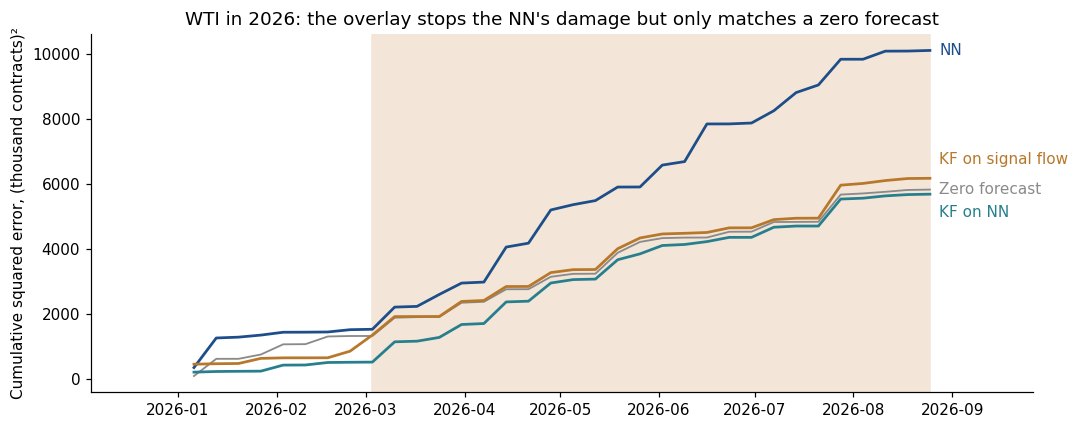

In [15]:
wti = samples["Jan-Aug 2026"].query("market == 'WTI'").sort_values("report_week_tuesday").set_index("report_week_tuesday")
fig, ax = plt.subplots(figsize=(10, 4))
for name, color, lw, shift in [("Zero", ZERO_COLOR, 1.2, 0), ("NN", NN_COLOR, 1.8, 0), ("KF on NN", BRENT, 1.8, -12), ("KF on signal flow", WTI, 1.8, 12)]:
    path = (((wti["actual_change"] - wti[name]) / 1e3) ** 2).cumsum()
    ax.plot(path.index, path, color=color, lw=lw)
    ax.annotate(name if name != "Zero" else "Zero forecast", (path.index[-1], path.iloc[-1]), xytext=(6, shift), textcoords="offset points", color=color, va="center")
ax.axvspan(WAR, END, color=WAR_SHADE, zorder=0)
ax.set(ylabel="Cumulative squared error, (thousand contracts)²", title="WTI in 2026: the overlay stops the NN's damage but only matches a zero forecast")
ax.margins(x=0.14)
fig.tight_layout()
fig.savefig(OUTPUT / "wti_2026_errors.png", dpi=170)
plt.show()

## 8. All 18 markets

The Brent notebook asked whether the 2026 change is WTI-specific. We fit the same scalar model to every market. Maximum likelihood often puts $q$ at zero, which would freeze beta and give a falsely tight band, so we fix $q_n$ at the cross-market median to make the bands comparable. The z-score compares the end-of-sample beta with the market's own 2015-2024 slope, treated as known (a small understatement of the noise); we repeat it at each market's own $q$, and correct for 18 two-sided tests with Benjamini-Hochberg. Markets whose signals were mostly capped in May-August have a beta that cannot have updated much, and we flag them.

Median q_n used: 3.85e-04; markets with q at zero under maximum likelihood: 1 of 18
        q_n at the MLE  Slope 2015-2024  Beta, end    SD  z against 2015-2024  Beta, end, own q  z, own q  May-Aug weeks with 2+ capped  BH q  BH q, own q                      Flag
Market                                                                                                                                                                              
WTI            2.2e-03            0.246      0.128 0.046               -2.592             0.078    -2.049                         0.294 0.043        0.182                          
CT             4.7e-04            0.025      0.021 0.005               -0.842             0.021    -0.802                         0.118 0.546        0.507                          
W              2.1e-05            0.045      0.039 0.008               -0.698             0.039    -1.516                         0.118 0.546        0.325                          
RBOB       

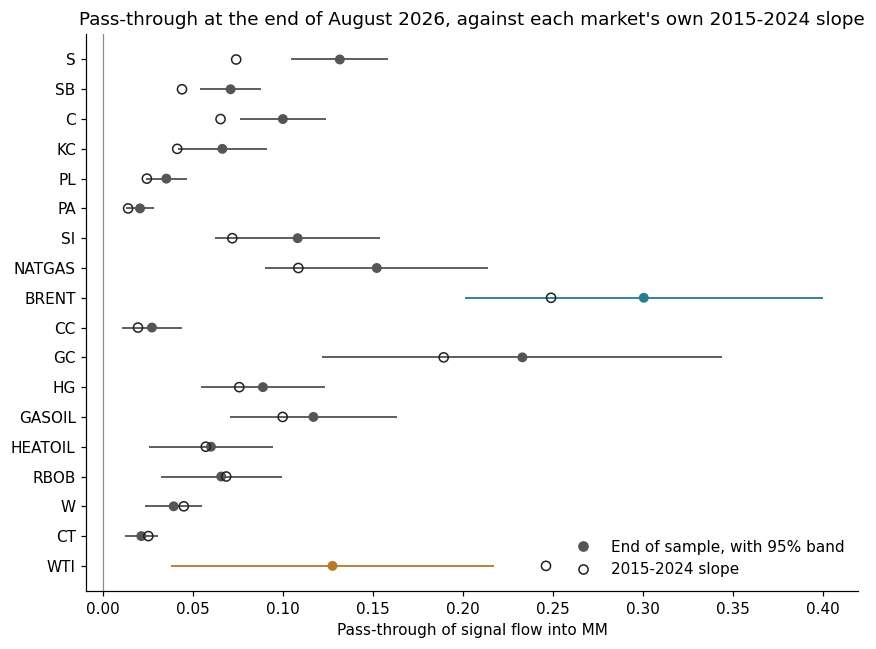

In [16]:
rows = []
fits = {m: kl.clean_xy(d_mm[m].loc["2011-01-11":], flow[m].loc["2011-01-11":]) for m in ct.ENERGY + ct.OTHER}
mles = {m: kl.uni_mle(*xy) for m, xy in fits.items()}
qn_median = np.median([m["qn"] for m in mles.values()])
for market, (y, x) in fits.items():
    result = kl.uni_fit(y, x, q=qn_median / mles[market]["scale"])
    sample = pd.concat([d_mm[market], flow[market]], axis=1, keys=["y", "x"]).loc["2015":"2024"].dropna()
    baseline = sample["x"] @ sample["y"] / (sample["x"] @ sample["x"])
    sd = np.sqrt(result["P_s"][-1])
    capped = (T.n_capped[market].loc["2026-05-01":"2026-08-31"] >= 2).mean()
    own = kl.uni_fit(y, x)
    rows.append({"Market": market, "q_n at the MLE": mles[market]["qn"], "Slope 2015-2024": baseline, "Beta, end": result["a_s"][-1], "SD": sd,
                 "z against 2015-2024": (result["a_s"][-1] - baseline) / sd, "Beta, end, own q": own["a_s"][-1],
                 "z, own q": (own["a_s"][-1] - baseline) / np.sqrt(own["P_s"][-1]), "May-Aug weeks with 2+ capped": capped})
table = pd.DataFrame(rows).set_index("Market")


def bh_q(p):
    order = np.argsort(p)
    q = np.minimum.accumulate((p[order] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    return pd.Series(np.minimum(q, 1.0), index=order).sort_index().to_numpy()


table["BH q"] = bh_q(2 * stats.norm.sf(table["z against 2015-2024"].abs().to_numpy()))
table["BH q, own q"] = bh_q(2 * stats.norm.sf(table["z, own q"].abs().to_numpy()))
table["Flag"] = np.where(table["May-Aug weeks with 2+ capped"] >= 0.75, "Mostly capped in May-Aug", "")
print(f"Median q_n used: {qn_median:.2e}; markets with q at zero under maximum likelihood: {(table['q_n at the MLE'] == 0).sum()} of 18")
print(table.sort_values("z against 2015-2024").assign(**{"q_n at the MLE": table["q_n at the MLE"].map("{:.1e}".format)}).to_string())

shown = table.sort_values("z against 2015-2024")
fig, ax = plt.subplots(figsize=(8, 6))
position = np.arange(len(shown))
colors = [WTI if m == "WTI" else BRENT if m == "BRENT" else "#555555" for m in shown.index]
ax.errorbar(shown["Beta, end"], position, xerr=1.96 * shown["SD"], fmt="none", ecolor=colors, elinewidth=1.2)
ax.scatter(shown["Beta, end"], position, c=colors, s=30, zorder=3, label="End of sample, with 95% band")
ax.scatter(shown["Slope 2015-2024"], position, facecolors="none", edgecolors="#222222", s=36, zorder=3, label="2015-2024 slope")
ax.set_yticks(position, shown.index)
ax.axvline(0, color=ZERO_COLOR, lw=0.8)
ax.set(xlabel="Pass-through of signal flow into MM", title="Pass-through at the end of August 2026, against each market's own 2015-2024 slope")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#555555", label="End of sample, with 95% band"),
                   Line2D([], [], marker="o", ls="", mfc="none", mec="#222222", label="2015-2024 slope")], frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT / "all_markets.png", dpi=170)
plt.show()

**Reading.**

- **WTI stands out on the downside, but the size of that depends on the prior.** It is the lowest of the 18 (z = -2.59, BH q = 0.043 at the common $q$). At its own larger $q$, z = -2.05 and q = 0.182. We treat this as suggestive.
- **There is no general exit from US-listed commodities.** Soybeans (z = 4.19), sugar (3.14) and corn (2.83) sit above their own 2015-2024 slopes under either $q$ (BH q at most 0.028). Wheat and cotton are slightly lower and not significant. On this measure the fall is specific to WTI, which speaks to the question in the team's comment. Tariffs and other causes were not tested.
- **Products cannot be read.** Gasoil, heating oil and RBOB are flagged, because their betas barely had a chance to update.
- **Brent is unremarkable**: 0.301 against 0.249 (z = 1.01, q = 0.546).

## Note: the link to the network's bias penalty

The paper's network has a time-varying bias with penalty $\lambda \sum (\Delta b)^2$ on top of a mean squared error over $T$ weeks and $M$ markets. Multiplying that objective by $TM$ gives $\sum e^2 + \lambda T M \sum (\Delta b)^2$. A Gaussian random walk gives $\sum e^2 + (R/Q_b) \sum (\Delta b)^2$. So the penalty is a Kalman prior with

$$\frac{Q_b}{R} = \frac{1}{\lambda T M} = \frac{1}{0.01 \times 104 \times 6} = 0.16,$$

for our rolling fit. The discretionary component in the network is therefore a smoothed state, and the same machinery could be run on levels. We did not fit that level model here.

## Save results

In [17]:
paths.to_csv(OUTPUT / "brent_wti_paths.csv")
changes.to_csv(OUTPUT / "spread_changes.csv")
robustness.to_csv(OUTPUT / "robustness.csv")
power.to_csv(OUTPUT / "power.csv")
gains.to_csv(OUTPUT / "nowcast_gains.csv")
table.to_csv(OUTPUT / "all_markets.csv")
print(sorted(path.name for path in OUTPUT.iterdir()))

['all_markets.csv', 'all_markets.png', 'beta_paths.png', 'brent_wti_paths.csv', 'nowcast_gains.csv', 'power.csv', 'return_response.png', 'robustness.csv', 'spread_changes.csv', 'wti_2026_errors.png']


## References

- Durbin, J. and Koopman, S. J. (2012). *Time Series Analysis by State Space Methods*, 2nd ed. Oxford University Press.
- Hansen, B. E. (1992). Testing for parameter instability in linear models. *Journal of Policy Modeling*, 14(4).
- Nyblom, J. (1989). Testing for the constancy of parameters over time. *Journal of the American Statistical Association*, 84(405).
- Sun, Bouchouev and Fattouh (2026), the Strait of Hormuz comment, in `references/`.
- OIES Insight 177 and Kestner (2020), used throughout the replication.